In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

print("Libraries loaded successfully")

Libraries loaded successfully


In [2]:
df = pd.read_csv("gcp_final_approved_dataset.csv")

print("Dataset loaded successfully")
print("Rows:", len(df))
print("Columns:", len(df.columns))

Dataset loaded successfully
Rows: 1000
Columns: 15


In [5]:
# Prepare dates and standardize column names

df.columns = [
    "resource_id",
    "service",
    "usage_qty",
    "usage_unit",
    "region",
    "cpu",
    "mem",
    "net_in",
    "net_out",
    "start",
    "end",
    "price_usd",
    "cost_usd",
    "cost_usd_rounded",
    "cost_inr"
]

df["start"] = pd.to_datetime(
    df["start"],
    dayfirst=True,
    errors="coerce"
)

df["end"] = pd.to_datetime(
    df["end"],
    dayfirst=True,
    errors="coerce"
)

df["date"] = df["start"].dt.normalize()

daily = (
    df.groupby("date")
      .agg(
          cost=("cost_usd", "sum"),
          n_records=("cost_usd", "size")
      )
)

daily = daily.loc["2024-07-01":"2024-08-28"]

daily = daily.reindex(
    pd.date_range(daily.index.min(), daily.index.max()),
    fill_value=0
)

daily["cost_k"] = daily["cost"] / 1000

print("Daily data prepared successfully")
print("Number of days:", len(daily))
print(
    "Date range:",
    daily.index.min().date(),
    "to",
    daily.index.max().date()
)

Daily data prepared successfully
Number of days: 59
Date range: 2024-07-01 to 2024-08-28


In [6]:
# Load Model 1 posterior samples from Member 3

saved = np.load("model1_forecast_samples.npz")

alpha_samples = saved["alpha"].reshape(-1)
beta_samples = saved["beta"].reshape(-1)
sigma_samples = saved["sigma"].reshape(-1)
nu_samples = saved["nu"].reshape(-1)

dow_eff_samples = saved["dow_eff"]
dow_eff_samples = dow_eff_samples.reshape(-1, 7)

print("Bayesian posterior samples loaded successfully")
print("Number of posterior samples:", len(alpha_samples))

Bayesian posterior samples loaded successfully
Number of posterior samples: 4000


In [7]:
# MEMBER 4 — 30-Day Bayesian Forecast

T = len(daily)

# Future 30 days
future_dates = pd.date_range(
    daily.index[-1] + pd.Timedelta(days=1),
    periods=30
)

# Model 1 time index
future_days = np.arange(T, T + 30)
future_t = future_days / (T - 1)

# Day of week for each future date
future_dow = future_dates.dayofweek.to_numpy()

# Use all 4,000 posterior samples
n_draws = len(alpha_samples)

rng = np.random.default_rng(42)

# Store simulated daily costs
future_costs = np.zeros((n_draws, 30))

for i in range(n_draws):

    # Expected standardized cost
    mu_future = (
        alpha_samples[i]
        + beta_samples[i] * future_t
        + dow_eff_samples[i, future_dow]
    )

    # Student-t random noise
    noise = stats.t.rvs(
        df=nu_samples[i],
        loc=0,
        scale=sigma_samples[i],
        size=30,
        random_state=rng
    )

    # Convert standardized prediction back to $ thousands
    future_z = mu_future + noise
    future_costs[i, :] = future_z * daily["cost_k"].std() + daily["cost_k"].mean()

# Total cost for each simulated 30-day future
total_30day_k = future_costs.sum(axis=1)

print("30-day forecasting completed successfully")
print("Simulated futures:", n_draws)
print("Forecast days:", len(future_dates))

30-day forecasting completed successfully
Simulated futures: 4000
Forecast days: 30


In [8]:
# 30-day forecast summary

median_k = np.percentile(total_30day_k, 50)
lower_k = np.percentile(total_30day_k, 3)
upper_k = np.percentile(total_30day_k, 97)

print("30-DAY BAYESIAN FORECAST")
print("=" * 35)

print(f"Median forecast: ${median_k * 1000:,.2f}")

print(
    f"94% predictive interval: "
    f"${lower_k * 1000:,.2f} to ${upper_k * 1000:,.2f}"
)

30-DAY BAYESIAN FORECAST
Median forecast: $793,267.40
94% predictive interval: $518,123.29 to $1,077,778.36


In [9]:
# Budget exceedance probability

# Data-based planning budget:
# 30 days × average historical daily cost
planning_budget = daily["cost"].mean() * 30

# Probability that simulated 30-day cost exceeds the budget
prob_exceed = np.mean((total_30day_k * 1000) > planning_budget)

print("BUDGET RISK ANALYSIS")
print("=" * 35)

print(f"Planning budget: ${planning_budget:,.2f}")
print(f"Probability of exceeding budget: {prob_exceed:.2%}")

BUDGET RISK ANALYSIS
Planning budget: $1,073,313.26
Probability of exceeding budget: 3.17%


In [10]:
# Optimization: identify potentially idle resources

idle_mask = (df["cpu"] < 20) & (df["mem"] < 20)

idle_count = idle_mask.sum()
idle_cost = df.loc[idle_mask, "cost_usd"].sum()
total_historical_cost = df["cost_usd"].sum()

idle_cost_share = idle_cost / total_historical_cost

print("RESOURCE OPTIMIZATION ANALYSIS")
print("=" * 40)

print(f"Potentially idle resources: {idle_count}")
print(f"Historical cost of idle resources: ${idle_cost:,.2f}")
print(f"Idle-resource cost share: {idle_cost_share:.2%}")

RESOURCE OPTIMIZATION ANALYSIS
Potentially idle resources: 26
Historical cost of idle resources: $63,003.67
Idle-resource cost share: 2.95%


In [11]:
# Optimization scenario analysis

# Assume we can eliminate 50% or 100% of the
# historical cost associated with potentially idle resources.
savings_50 = total_30day_k * idle_cost_share * 0.50
savings_100 = total_30day_k * idle_cost_share * 1.00

optimized_50 = total_30day_k - savings_50
optimized_100 = total_30day_k - savings_100

print("OPTIMIZATION SCENARIO ANALYSIS")
print("=" * 40)

print(f"Median 30-day forecast: ${median_k * 1000:,.2f}")

print(
    f"50% idle-resource optimization: "
    f"${np.median(optimized_50) * 1000:,.2f}"
)

print(
    f"100% idle-resource optimization: "
    f"${np.median(optimized_100) * 1000:,.2f}"
)

print(
    f"Potential median savings at 50% optimization: "
    f"${np.median(savings_50) * 1000:,.2f}"
)

print(
    f"Potential median savings at 100% optimization: "
    f"${np.median(savings_100) * 1000:,.2f}"
)

OPTIMIZATION SCENARIO ANALYSIS
Median 30-day forecast: $793,267.40
50% idle-resource optimization: $781,563.95
100% idle-resource optimization: $769,860.51
Potential median savings at 50% optimization: $11,703.45
Potential median savings at 100% optimization: $23,406.90


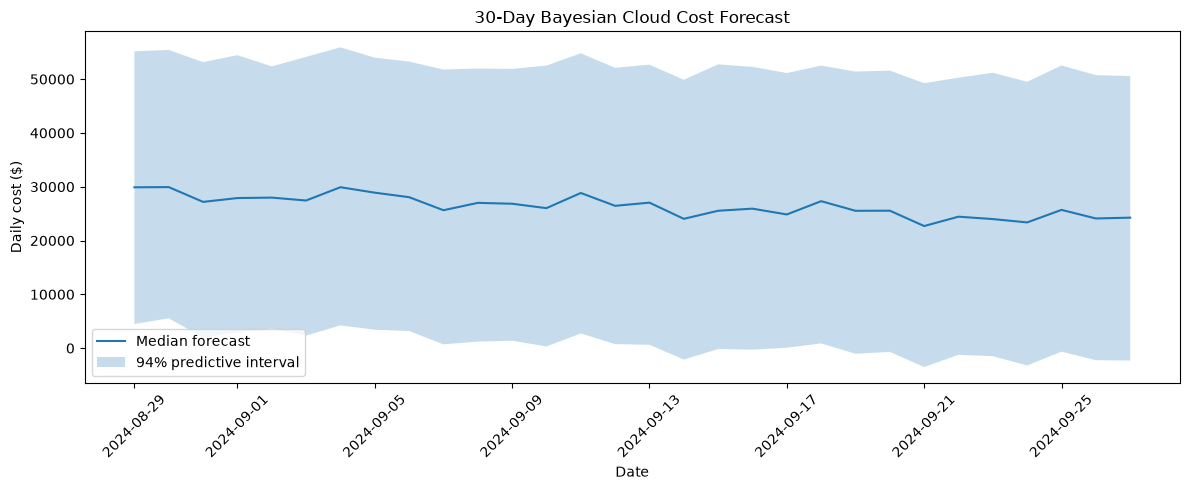

In [12]:
# 30-day forecast visualization

daily_forecast_median = np.median(future_costs, axis=0)
daily_forecast_lower = np.percentile(future_costs, 3, axis=0)
daily_forecast_upper = np.percentile(future_costs, 97, axis=0)

plt.figure(figsize=(12, 5))

plt.plot(
    future_dates,
    daily_forecast_median * 1000,
    label="Median forecast"
)

plt.fill_between(
    future_dates,
    daily_forecast_lower * 1000,
    daily_forecast_upper * 1000,
    alpha=0.25,
    label="94% predictive interval"
)

plt.xlabel("Date")
plt.ylabel("Daily cost ($)")
plt.title("30-Day Bayesian Cloud Cost Forecast")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()